# Fusion des branches vidéo, audio et texte

**Objectif** : combiner les probabilités produites par chaque branche (8 émotions par clip) en une seule décision.

**Type de fusion** : *tardive* (late fusion). Chaque branche reste indépendante ; on ne combine que ses 8 probabilités
de sortie. C'est la seule fusion possible avec ce qui a été exporté (des probabilités, pas d'embeddings), et elle gère
facilement une modalité absente.

**Méthodes comparées** :

| Méthode | Principe |
|---|---|
| Vote majoritaire | chaque modalité vote pour sa classe la plus probable ; la classe qui a le plus de voix gagne |
| Max | on garde la probabilité la plus élevée, toutes modalités confondues : la modalité la plus sûre d'elle décide |
| **Moyenne** (idée principale du groupe) | moyenne des probabilités des modalités, puis classe la plus probable |
| Moyenne pondérée | idem, avec un poids par modalité réglé sur le dev |

Chaque méthode est testée **avec et sans masque de disponibilité** :
- l'**audio** n'est pris en compte que si le clip contient de la parole (Silero VAD) : sur les clips sans parole, le modèle
  audio (wav2vec2 entraîné sur de la voix) est au niveau du hasard ;
- le **texte** n'est pris en compte que si le clip a une transcription exploitable (pas une hallucination de Whisper).

**Protocole** :
- même split que les branches (`Group_1.csv` : 250 / 50 / 50 films → 2 207 / 442 / 439 clips) ;
- **tous les choix** (méthode, poids, masque) se font sur le **dev** ; le **test** est mesuré à la fin ;
- mesure principale : F1 macro, avec un intervalle de confiance à 95 % par bootstrap sur les films (comme la branche
  vidéo). On donne aussi l'exactitude et la valence (positif / négatif).

**Plan** :
0. Configuration
1. Table de référence des clips (split, émotion, parole, texte)
2. Chargement des probabilités de chaque branche
3. Mesures
4. Chaque modalité seule
5. Méthodes de fusion sans réglage (vote, max, moyenne)
6. Moyenne pondérée (poids réglés sur le dev)
7. Récapitulatif et choix final
8. Analyse : ce que la fusion corrige et ce qu'elle casse
9. Sauvegarde

## 0. Configuration

In [ ]:
import json, sys, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay

# Sur Colab : mettre les fichiers ci-dessous dans un dossier du Drive et adapter DATA_DIR.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/Projet Multimedia/fusion ")
else:
    DATA_DIR = Path("donnees")
OUT_DIR = DATA_DIR / "outputs_fusion"
OUT_DIR.mkdir(parents=True, exist_ok=True)

FICHIERS = {
    "clips":   DATA_DIR / "dataset_complet_clips.csv",   # un clip par ligne + émotion
    "split":   DATA_DIR / "Group_1.csv",                 # film_id -> train / dev / test
    "vad":     DATA_DIR / "vad_results.json",            # présence de parole (Silero VAD)
    "texte":   DATA_DIR / "dataset.csv",                 # clips transcrits (branche texte)
}
# Probabilités de chaque branche : {modalité: {split: fichier}}.
# Une modalité dont les fichiers n'existent pas encore est simplement ignorée.
PROBAS = {
    "video": {"dev": DATA_DIR / "probs_video_dev.csv",          "test": DATA_DIR / "probs_video_test.csv"},
    "audio": {"dev": DATA_DIR / "probabilites_audio_dev.csv",   "test": DATA_DIR / "probabilites_audio_test.csv"},
    "texte": {"dev": DATA_DIR / "probs_texte_dev.csv",          "test": DATA_DIR / "probs_texte_test.csv"},
}

CLASSES = ["amusement", "awe", "contentment", "excitement", "anger", "disgust", "fear", "sadness"]
VALENCE = np.array([1, 1, 1, 1, 0, 0, 0, 0])   # 1 = positif, 0 = négatif
SPLITS = ["dev", "test"]
SEED = 42

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Table de référence des clips

Une ligne par clip : film, split, émotion, et deux indicateurs de disponibilité :
- `parole` : le clip contient de la parole selon Silero VAD ;
- `texte_ok` : le clip a une transcription **exploitable**. On écarte les hallucinations de Whisper repérées dans
  l'analyse (transcriptions surtout en caractères non latins, ex. « 睡着 », « パスパスパス ») et les transcriptions
  d'un seul mot.

In [ ]:
clips = pd.read_csv(FICHIERS["clips"], dtype={"film_id": str})
doublons = clips["video_id"].str.contains(r"\(", regex=True)          # ex. "00273_clip_005 (1)" : copie de fichier
print("Lignes écartées (copies de fichiers) :", clips.loc[doublons, "video_id"].tolist())
clips = clips[~doublons].copy()
clips["film_id"] = clips["video_id"].str.split("_").str[0]

split_films = pd.read_csv(FICHIERS["split"], dtype=str).set_index("film_id")["split"]
clips["split"] = clips["film_id"].map(split_films)
assert clips["split"].notna().all(), "des films n'ont pas de split"
clips["label"] = clips["emotion"].map({c: i for i, c in enumerate(CLASSES)})

vad = json.load(open(FICHIERS["vad"]))["results"]
clips["parole"] = clips["video_id"].map(lambda v: vad[v]["has_speech"])

def texte_exploitable(t, min_mots=2, max_non_latin=0.3):
    # Écarte les transcriptions vides, trop courtes ou surtout en caractères non latins (hallucinations Whisper)
    if not isinstance(t, str) or len(t.split()) < min_mots:
        return False
    lettres = [ch for ch in t if ch.isalpha()]
    return bool(lettres) and np.mean([ord(ch) > 0x24F for ch in lettres]) <= max_non_latin

texte = pd.read_csv(FICHIERS["texte"]).set_index("video_id")["text"]
clips["texte"] = clips["video_id"].isin(texte.index)
clips["texte_ok"] = clips["video_id"].map(texte).map(texte_exploitable).fillna(False).astype(bool)

clips = clips[["video_id", "film_id", "split", "emotion", "label", "parole", "texte", "texte_ok"]]
print(clips.groupby("split").agg(clips=("video_id", "size"), films=("film_id", "nunique"),
                                  avec_parole=("parole", "sum"), avec_texte=("texte", "sum"),
                                  texte_exploitable=("texte_ok", "sum")).loc[["train", "dev", "test"]])

Lignes écartées (copies de fichiers) : ['00273_clip_005 (1)']
       clips  films  avec_parole  avec_texte  texte_exploitable
split                                                          
train   2207    250         1428        1411               1378
dev      442     50          284         281                277
test     439     50          259         257                252


## 2. Chargement des probabilités de chaque branche

Les branches n'utilisent pas le même nom de colonnes (`video_anger`, `anger`…) : on les harmonise, puis on aligne chaque
modalité sur la table de référence. Un clip absent d'une modalité reçoit `NaN`.

In [ ]:
def charger(path):
    df = pd.read_csv(path)
    renomme = {}
    for col in df.columns:
        for c in CLASSES:
            if col == c or col.endswith("_" + c):     # "anger", "video_anger", "p_anger"...
                renomme[col] = c
    df = df.rename(columns=renomme)
    if not all(c in df.columns for c in CLASSES):    # format p_0 ... p_7
        df = df.rename(columns={f"p_{k}": c for k, c in enumerate(CLASSES)})
    assert all(c in df.columns for c in CLASSES), f"{path.name} : colonnes de probabilités introuvables"
    assert not df["video_id"].duplicated().any(), f"{path.name} : video_id en double"
    return df.set_index("video_id")[CLASSES]

ref = {s: clips[clips["split"] == s].reset_index(drop=True) for s in SPLITS}
y = {s: ref[s]["label"].values for s in SPLITS}
films = {s: ref[s]["film_id"].values for s in SPLITS}

P = {}   # P[modalité][split] : tableau (n_clips, 8), NaN si le clip n'a pas cette modalité
for mod, chemins in PROBAS.items():
    if not all(p.exists() for p in chemins.values()):
        print(f"{mod:6s} : fichiers absents -> modalité ignorée")
        continue
    P[mod] = {}
    for s in SPLITS:
        df = charger(chemins[s])
        sommes = df.sum(axis=1)
        assert np.allclose(sommes, 1, atol=1e-3), f"{mod}/{s} : les probabilités ne somment pas à 1"
        inconnus = set(df.index) - set(ref[s]["video_id"])
        assert not inconnus, f"{mod}/{s} : {len(inconnus)} clips hors du split, ex. {list(inconnus)[:3]}"
        P[mod][s] = df.reindex(ref[s]["video_id"]).values
        n_ok = (~np.isnan(P[mod][s][:, 0])).sum()
        print(f"{mod:6s} {s:4s} : {n_ok}/{len(ref[s])} clips")
MODALITES = list(P)
print("Modalités disponibles :", MODALITES)

video  dev  : 442/442 clips
video  test : 439/439 clips
audio  dev  : 442/442 clips
audio  test : 439/439 clips
texte  dev  : 281/442 clips
texte  test : 257/439 clips
Modalités disponibles : ['video', 'audio', 'texte']


### Masques de disponibilité

Pour chaque clip et chaque modalité : la modalité est-elle utilisée dans la fusion ?
- **sans masque** : une modalité est utilisée dès qu'elle a une prédiction pour le clip ;
- **avec masque** : l'audio seulement si le clip contient de la parole, le texte seulement si la transcription est exploitable.

La vidéo est toujours présente : chaque clip a donc au moins une modalité.

In [ ]:
def masques(split, avec_masque):
    m = {mod: ~np.isnan(P[mod][split][:, 0]) for mod in MODALITES}
    if avec_masque:
        if "audio" in m:
            m["audio"] &= ref[split]["parole"].values
        if "texte" in m:
            m["texte"] &= ref[split]["texte_ok"].values
    return m

for s in SPLITS:
    for am in (False, True):
        m = masques(s, am)
        combis = pd.Series(["+".join(k for k in MODALITES if m[k][i]) for i in range(len(ref[s]))]).value_counts()
        print(f"{s} {'avec' if am else 'sans'} masque :", combis.to_dict())

dev sans masque : {'video+audio+texte': 281, 'video+audio': 161}
dev avec masque : {'video+audio+texte': 277, 'video': 158, 'video+audio': 7}
test sans masque : {'video+audio+texte': 257, 'video+audio': 182}
test avec masque : {'video+audio+texte': 252, 'video': 180, 'video+audio': 7}


## 3. Mesures

F1 macro (mesure principale), exactitude et valence. L'intervalle de confiance à 95 % est obtenu par **bootstrap sur
les films** : les clips d'un même film sont corrélés, rééchantillonner les clips sous-estimerait l'incertitude.

`gain_vs` compare deux méthodes sur **les mêmes** échantillons bootstrap (comparaison appariée) : on obtient
l'intervalle du gain et la proportion d'échantillons où la méthode fait mieux.

In [ ]:
rng = np.random.default_rng(SEED)
BOOT = {}
for s in SPLITS:   # mêmes tirages de films pour toutes les méthodes -> comparaisons appariées
    uniq = np.unique(films[s])
    idx_film = {f: np.flatnonzero(films[s] == f) for f in uniq}
    BOOT[s] = [np.concatenate([idx_film[f] for f in rng.choice(uniq, size=len(uniq))]) for _ in range(1000)]

def f1m(yt, yp):
    return f1_score(yt, yp, average="macro", labels=range(len(CLASSES)), zero_division=0)

def mesures(pred, split):
    yt = y[split]
    boot = [f1m(yt[i], pred[i]) for i in BOOT[split]]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"F1": f1m(yt, pred), "IC_bas": lo, "IC_haut": hi,
            "exactitude": accuracy_score(yt, pred), "valence": np.mean(VALENCE[pred] == VALENCE[yt])}

def gain_vs(pred_a, pred_b, split):
    yt = y[split]
    d = np.array([f1m(yt[i], pred_a[i]) - f1m(yt[i], pred_b[i]) for i in BOOT[split]])
    lo, hi = np.percentile(d, [2.5, 97.5])
    return f1m(yt, pred_a) - f1m(yt, pred_b), lo, hi, (d > 0).mean()

for s in SPLITS:
    maj = np.bincount(y[s]).argmax()
    print(f"{s} : prédire toujours « {CLASSES[maj]} » -> exactitude {np.mean(y[s] == maj):.3f}, "
          f"F1 macro {f1m(y[s], np.full_like(y[s], maj)):.3f} ; hasard ≈ 0.125")

dev : prédire toujours « anger » -> exactitude 0.222, F1 macro 0.045 ; hasard ≈ 0.125
test : prédire toujours « anger » -> exactitude 0.219, F1 macro 0.045 ; hasard ≈ 0.125


## 4. Chaque modalité seule (point de comparaison)

In [ ]:
lignes = []
for mod in MODALITES:
    for s in SPLITS:
        dispo = ~np.isnan(P[mod][s][:, 0])
        pred = np.nan_to_num(P[mod][s], nan=0).argmax(1)
        r = {"modalité": mod, "split": s, "clips couverts": int(dispo.sum())}
        r["F1 (clips couverts)"] = f1m(y[s][dispo], pred[dispo])
        if mod == "audio":
            par = ref[s]["parole"].values
            r["F1 clips avec parole"] = f1m(y[s][par], pred[par])
            r["F1 clips sans parole"] = f1m(y[s][~par], pred[~par])
        lignes.append(r)
seules = pd.DataFrame(lignes)
print(seules.round(3).to_string(index=False))

modalité split  clips couverts  F1 (clips couverts)  F1 clips avec parole  F1 clips sans parole
   video   dev             442                0.390                   NaN                   NaN
   video  test             439                0.369                   NaN                   NaN
   audio   dev             442                0.262                 0.247                 0.152
   audio  test             439                0.220                 0.202                 0.149
   texte   dev             281                0.187                   NaN                   NaN
   texte  test             257                0.179                   NaN                   NaN


L'audio est correct sur les clips avec parole et **au niveau du hasard sans parole**. C'est la justification du masque.

## 5. Méthodes de fusion sans réglage

Pour un clip, on note $p_m$ le vecteur des 8 probabilités de la modalité $m$, et $M$ l'ensemble des modalités
disponibles (selon le masque).

- **Vote majoritaire** : chaque modalité de $M$ vote pour $\arg\max_k p_m(k)$. En cas d'égalité (fréquent avec deux
  modalités qui ne sont pas d'accord), on départage par la probabilité moyenne des classes à égalité.
  *Remarque* : avec deux modalités, le vote se ramène presque toujours à la moyenne ; il n'a de sens propre qu'à partir
  de trois modalités.
- **Max** : $\hat y = \arg\max_k \max_{m \in M} p_m(k)$. La classe gagnante est celle qui a la probabilité la plus haute
  dans n'importe quelle modalité : c'est la modalité **la plus confiante** qui décide.
- **Moyenne** : $\hat y = \arg\max_k \frac{1}{|M|}\sum_{m \in M} p_m(k)$.
- **Moyenne géométrique** (variante) : moyenne des log-probabilités. Une modalité qui juge une classe très improbable
  peut l'éliminer.

In [ ]:
def empiler(split, avec_masque):
    # (n_modalités, n_clips, 8) avec NaN là où la modalité n'est pas utilisée
    m = masques(split, avec_masque)
    return np.stack([np.where(m[mod][:, None], P[mod][split], np.nan) for mod in MODALITES])

def vote_majoritaire(S):
    dispo = ~np.isnan(S[:, :, 0])
    votes = np.zeros(S.shape[1:])
    for k in range(S.shape[0]):
        choix = np.nan_to_num(S[k], nan=-1).argmax(1)
        votes[np.arange(S.shape[1])[dispo[k]], choix[dispo[k]]] += 1
    moy = np.nanmean(S, axis=0)
    candidats = votes == votes.max(1, keepdims=True)        # classes à égalité de voix
    return np.where(candidats, moy, -np.inf).argmax(1)       # départage par la probabilité moyenne

def regle_max(S):
    return np.nanmax(S, axis=0).argmax(1)

def moyenne(S, poids=None):
    w = np.ones(S.shape[0]) if poids is None else np.asarray(poids, float)
    dispo = ~np.isnan(S[:, :, 0])
    W = w[:, None] * dispo                                   # poids renormalisés clip par clip
    W = W / W.sum(0, keepdims=True)
    return np.einsum("mn,mnk->nk", W, np.nan_to_num(S))      # probabilités fusionnées (somment à 1)

def moyenne_geo(S, poids=None):
    w = np.ones(S.shape[0]) if poids is None else np.asarray(poids, float)
    dispo = ~np.isnan(S[:, :, 0])
    W = w[:, None] * dispo
    W = W / W.sum(0, keepdims=True)
    logp = np.einsum("mn,mnk->nk", W, np.log(np.clip(np.nan_to_num(S, nan=1), 1e-6, 1)))
    p = np.exp(logp - logp.max(1, keepdims=True))
    return p / p.sum(1, keepdims=True)

METHODES = {
    "vote majoritaire":   lambda S: vote_majoritaire(S),
    "max":                lambda S: regle_max(S),
    "moyenne":            lambda S: moyenne(S).argmax(1),
    "moyenne géométrique": lambda S: moyenne_geo(S).argmax(1),
}

PRED = {}       # PRED[(méthode, masque)][split] -> prédictions
resultats = []
for s in SPLITS:
    for mod in MODALITES:   # références : chaque modalité seule (la vidéo couvre tous les clips)
        if (~np.isnan(P[mod][s][:, 0])).all():
            PRED.setdefault((f"{mod} seule", "—"), {})[s] = P[mod][s].argmax(1)
    for am in (False, True):
        S = empiler(s, am)
        for nom, f in METHODES.items():
            PRED.setdefault((nom, "avec" if am else "sans"), {})[s] = f(S)
for (nom, masque), preds in PRED.items():
    for s in SPLITS:
        resultats.append({"méthode": nom, "masque": masque, "split": s, **mesures(preds[s], s)})
res = pd.DataFrame(resultats)
tab = res.pivot_table(index=["méthode", "masque"], columns="split", values=["F1", "exactitude", "valence"], sort=False)
print(tab.round(3).to_string())

                               F1        exactitude        valence       
split                         dev   test        dev   test     dev   test
méthode             masque                                               
video seule         —       0.390  0.369      0.405  0.410   0.724  0.686
audio seule         —       0.262  0.220      0.276  0.241   0.604  0.608
vote majoritaire    sans    0.362  0.338      0.380  0.380   0.695  0.674
                    avec    0.372  0.338      0.391  0.380   0.699  0.677
max                 sans    0.319  0.313      0.339  0.353   0.658  0.638
                    avec    0.330  0.304      0.351  0.346   0.676  0.638
moyenne             sans    0.349  0.339      0.364  0.380   0.676  0.672
                    avec    0.360  0.329      0.376  0.374   0.688  0.672
moyenne géométrique sans    0.363  0.343      0.378  0.383   0.695  0.686
                    avec    0.377  0.326      0.391  0.369   0.708  0.683


## 6. Moyenne pondérée (poids réglés sur le dev)

Les modalités n'ont pas la même qualité (la vidéo est nettement meilleure) : une moyenne simple donne autant de poids à
la meilleure qu'à la plus faible. On cherche les poids $w_m$ (somme = 1, pas de 0,05) qui maximisent le **F1 macro sur
le dev**. Le test n'intervient pas dans ce choix.

Avec ~440 clips de dev, le F1 est bruité (±5 points) : on regarde la **courbe** autour de l'optimum plutôt que le seul
meilleur point, et on préfère un poids situé au milieu d'un plateau.

moyenne pondérée               sans masque : poids {'video': np.float64(0.5), 'audio': np.float64(0.4), 'texte': np.float64(0.1)} -> F1 dev 0.406
moyenne pondérée               avec masque : poids {'video': np.float64(0.5), 'audio': np.float64(0.4), 'texte': np.float64(0.1)} -> F1 dev 0.420
moyenne géométrique pondérée   sans masque : poids {'video': np.float64(0.65), 'audio': np.float64(0.3), 'texte': np.float64(0.05)} -> F1 dev 0.405
moyenne géométrique pondérée   avec masque : poids {'video': np.float64(0.4), 'audio': np.float64(0.45), 'texte': np.float64(0.15)} -> F1 dev 0.412


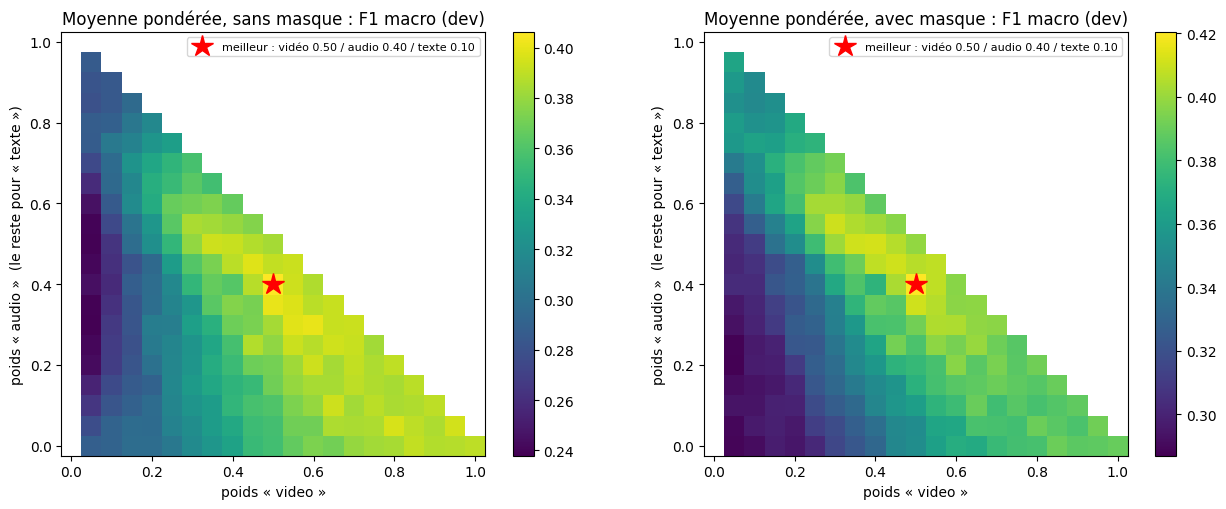

In [ ]:
def grille_poids(n, pas=0.05):
    vals = np.round(np.arange(0, 1 + 1e-9, pas), 2)
    return [w for w in itertools.product(vals, repeat=n) if abs(sum(w) - 1) < 1e-6 and w[0] > 0]

REGLES_PONDEREES = {"moyenne pondérée": moyenne, "moyenne géométrique pondérée": moyenne_geo}
POIDS = {}
courbes = {}
for nom, f in REGLES_PONDEREES.items():
    for am in (False, True):
        S_dev = empiler("dev", am)
        scores = [(w, f1m(y["dev"], f(S_dev, w).argmax(1))) for w in grille_poids(len(MODALITES))]
        w_best, f_best = max(scores, key=lambda t: t[1])
        POIDS[(nom, am)] = w_best
        courbes[(nom, am)] = scores
        cle = (nom, "avec" if am else "sans")
        PRED[cle] = {s: f(empiler(s, am), w_best).argmax(1) for s in SPLITS}
        print(f"{nom:30s} {'avec' if am else 'sans'} masque : poids {dict(zip(MODALITES, w_best))} "
              f"-> F1 dev {f_best:.3f}")

if len(MODALITES) == 2:   # avec deux modalités, un seul poids libre : on peut tracer la courbe
    fig, ax = plt.subplots(figsize=(7, 4))
    for (nom, am), scores in courbes.items():
        ax.plot([w[0] for w, _ in scores], [f for _, f in scores], "o-", ms=3,
                label=f"{nom}, {'avec' if am else 'sans'} masque")
    ax.set_xlabel(f"poids de la modalité « {MODALITES[0]} » (le reste pour « {MODALITES[1]} »)")
    ax.set_ylabel("F1 macro (dev)")
    ax.set_title("Choix du poids sur le dev")
    ax.grid(alpha=.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(OUT_DIR / "choix_poids_dev.png", dpi=150); plt.show()

elif len(MODALITES) == 3:   # deux poids libres (le 3e = 1 - les deux autres) : carte de chaleur
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    for ax, am in zip(axes, (False, True)):
        scores = courbes[("moyenne pondérée", am)]
        vals = np.round(np.arange(0, 1 + 1e-9, 0.05), 2)
        grille = np.full((len(vals), len(vals)), np.nan)          # lignes : poids audio, colonnes : poids vidéo
        for w, f in scores:
            grille[np.searchsorted(vals, w[1]), np.searchsorted(vals, w[0])] = f
        im = ax.imshow(grille, origin="lower", cmap="viridis", extent=(-0.025, 1.025, -0.025, 1.025))
        w_best = POIDS[("moyenne pondérée", am)]
        ax.plot(w_best[0], w_best[1], "r*", ms=16,
                label=f"meilleur : vidéo {w_best[0]:.2f} / audio {w_best[1]:.2f} / texte {w_best[2]:.2f}")
        ax.set_xlabel(f"poids « {MODALITES[0]} »")
        ax.set_ylabel(f"poids « {MODALITES[1]} »  (le reste pour « {MODALITES[2]} »)")
        ax.set_title(f"Moyenne pondérée, {'avec' if am else 'sans'} masque : F1 macro (dev)")
        ax.legend(loc="upper right", fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.savefig(OUT_DIR / "choix_poids_dev.png", dpi=150); plt.show()

## 7. Récapitulatif et choix final

**Règle de choix** : la méthode retenue est celle qui a le meilleur F1 macro **sur le dev**. Les scores sur le test
sont donnés pour toutes les méthodes, mais ils n'interviennent pas dans le choix.

In [ ]:
lignes = []
for (nom, masque), preds in PRED.items():
    r = {"méthode": nom, "masque": masque}
    for s in SPLITS:
        m = mesures(preds[s], s)
        r[f"F1 {s}"] = m["F1"]
        if s == "test":
            r["IC95 test"] = f"[{m['IC_bas']:.3f}, {m['IC_haut']:.3f}]"
        r[f"exactitude {s}"] = m["exactitude"]
        r[f"valence {s}"] = m["valence"]
    lignes.append(r)
recap = pd.DataFrame(lignes)

fusions = recap[~recap["méthode"].str.endswith("seule")]
choix = fusions.loc[fusions["F1 dev"].idxmax()]
CHOIX = (choix["méthode"], choix["masque"])
recap["retenu"] = np.where((recap["méthode"] == CHOIX[0]) & (recap["masque"] == CHOIX[1]), "←", "")
cols = ["méthode", "masque", "F1 dev", "F1 test", "IC95 test", "exactitude dev", "exactitude test",
        "valence dev", "valence test", "retenu"]
print(recap[cols].round(3).to_string(index=False))
print(f"\nMéthode retenue (meilleur F1 dev) : {CHOIX[0]}, {CHOIX[1]} masque")

ref_mod = "video seule"
for s in SPLITS:
    g, lo, hi, p = gain_vs(PRED[CHOIX][s], PRED[(ref_mod, "—")][s], s)
    print(f"Gain vs {ref_mod} sur le {s} : {g:+.3f} F1  IC95 [{lo:+.3f}, {hi:+.3f}]  "
          f"(meilleure dans {p:.0%} des tirages bootstrap)")
recap[cols].to_csv(OUT_DIR / "recapitulatif_fusion.csv", index=False)

                     méthode masque  F1 dev  F1 test      IC95 test  exactitude dev  exactitude test  valence dev  valence test retenu
                 video seule      —   0.390    0.369 [0.308, 0.421]           0.405            0.410        0.724         0.686       
                 audio seule      —   0.262    0.220 [0.170, 0.260]           0.276            0.241        0.604         0.608       
            vote majoritaire   sans   0.362    0.338 [0.273, 0.391]           0.380            0.380        0.695         0.674       
                         max   sans   0.319    0.313 [0.255, 0.362]           0.339            0.353        0.658         0.638       
                     moyenne   sans   0.349    0.339 [0.275, 0.389]           0.364            0.380        0.676         0.672       
         moyenne géométrique   sans   0.363    0.343 [0.277, 0.392]           0.378            0.383        0.695         0.686       
            vote majoritaire   avec   0.372    0.338 [0

## 8. Analyse : ce que la fusion corrige et ce qu'elle casse (test)

Clips corrigés par la fusion (vidéo faux -> fusion juste) : 17
Clips cassés par la fusion   (vidéo juste -> fusion faux) : 14

F1 par classe (test) :
             video seule  fusion retenue  écart
amusement          0.338           0.333 -0.004
awe                0.319           0.308 -0.011
contentment        0.444           0.439 -0.006
excitement         0.152           0.268  0.116
anger              0.526           0.545  0.019
disgust            0.278           0.286  0.007
fear               0.520           0.514 -0.005
sadness            0.372           0.317 -0.055
avec parole  (259 clips) : vidéo 0.383 -> fusion 0.384
sans parole  (180 clips) : vidéo 0.284 -> fusion 0.284


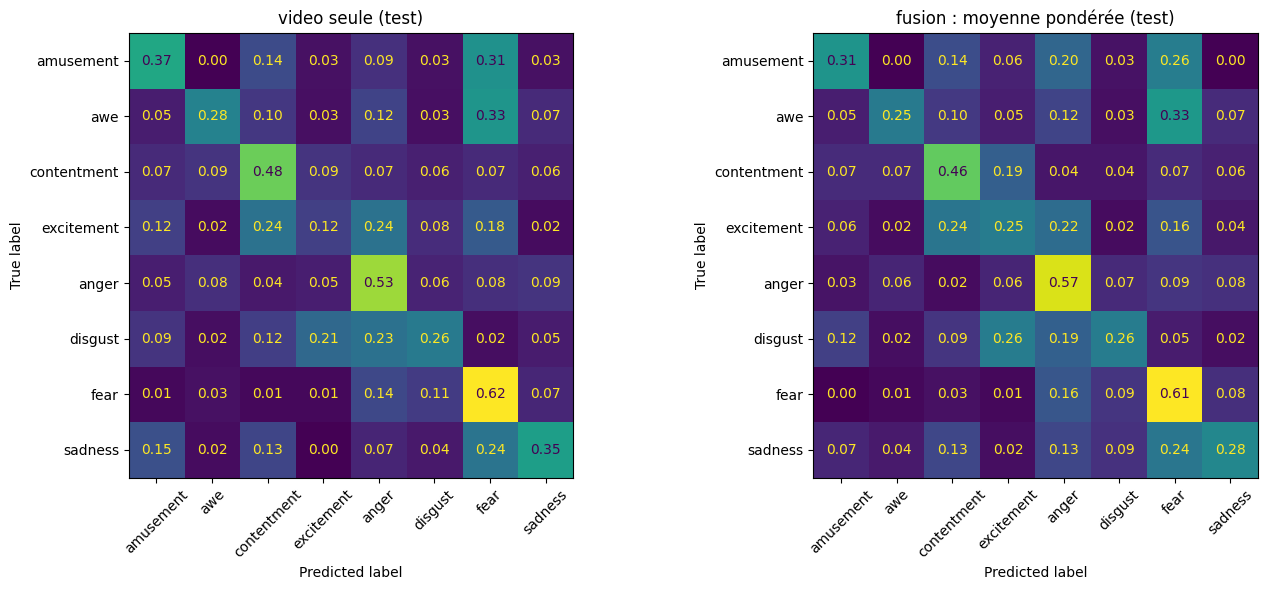

In [ ]:
s = "test"
pv, pf, yt = PRED[(ref_mod, "—")][s], PRED[CHOIX][s], y[s]
print(f"Clips corrigés par la fusion (vidéo faux -> fusion juste) : {np.sum((pv != yt) & (pf == yt))}")
print(f"Clips cassés par la fusion   (vidéo juste -> fusion faux) : {np.sum((pv == yt) & (pf != yt))}")

par_classe = pd.DataFrame({
    ref_mod: f1_score(yt, pv, average=None, labels=range(8), zero_division=0),
    "fusion retenue": f1_score(yt, pf, average=None, labels=range(8), zero_division=0),
}, index=CLASSES)
par_classe["écart"] = par_classe["fusion retenue"] - par_classe[ref_mod]
print("\nF1 par classe (test) :"); print(par_classe.round(3))

for nom, groupe in [("avec parole", ref[s]["parole"].values), ("sans parole", ~ref[s]["parole"].values)]:
    print(f"{nom:12s} ({groupe.sum()} clips) : vidéo {f1m(yt[groupe], pv[groupe]):.3f} -> "
          f"fusion {f1m(yt[groupe], pf[groupe]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (titre, p) in zip(axes, [(ref_mod, pv), (f"fusion : {CHOIX[0]}", pf)]):
    ConfusionMatrixDisplay.from_predictions(yt, p, display_labels=CLASSES, normalize="true", ax=ax,
                                            values_format=".2f", xticks_rotation=45, colorbar=False)
    ax.set_title(f"{titre} (test)")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_test.png", dpi=150); plt.show()

## 9. Sauvegarde

Probabilités fusionnées de la méthode retenue (pour le vote et le max, qui ne produisent pas de probabilités, on
sauvegarde la moyenne avec les mêmes masques), plus le tableau récapitulatif et les figures.

Fichiers prêts : ['choix_poids_dev.png', 'confusion_test.png', 'probs_fusion_dev.csv', 'probs_fusion_test.csv', 'recapitulatif_fusion.csv']


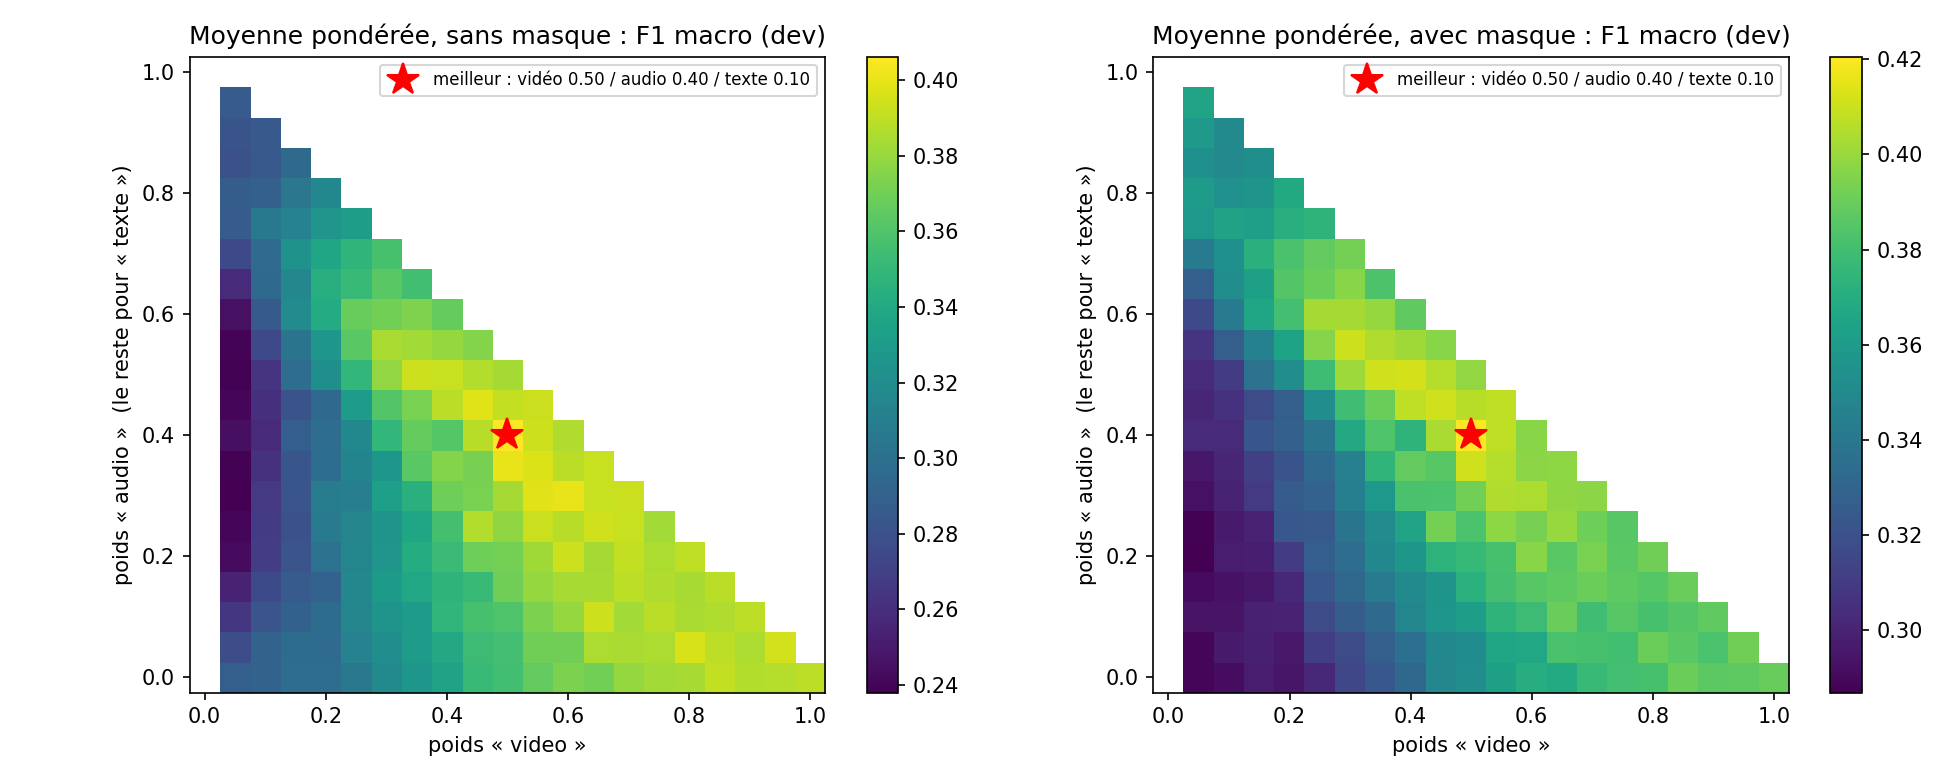

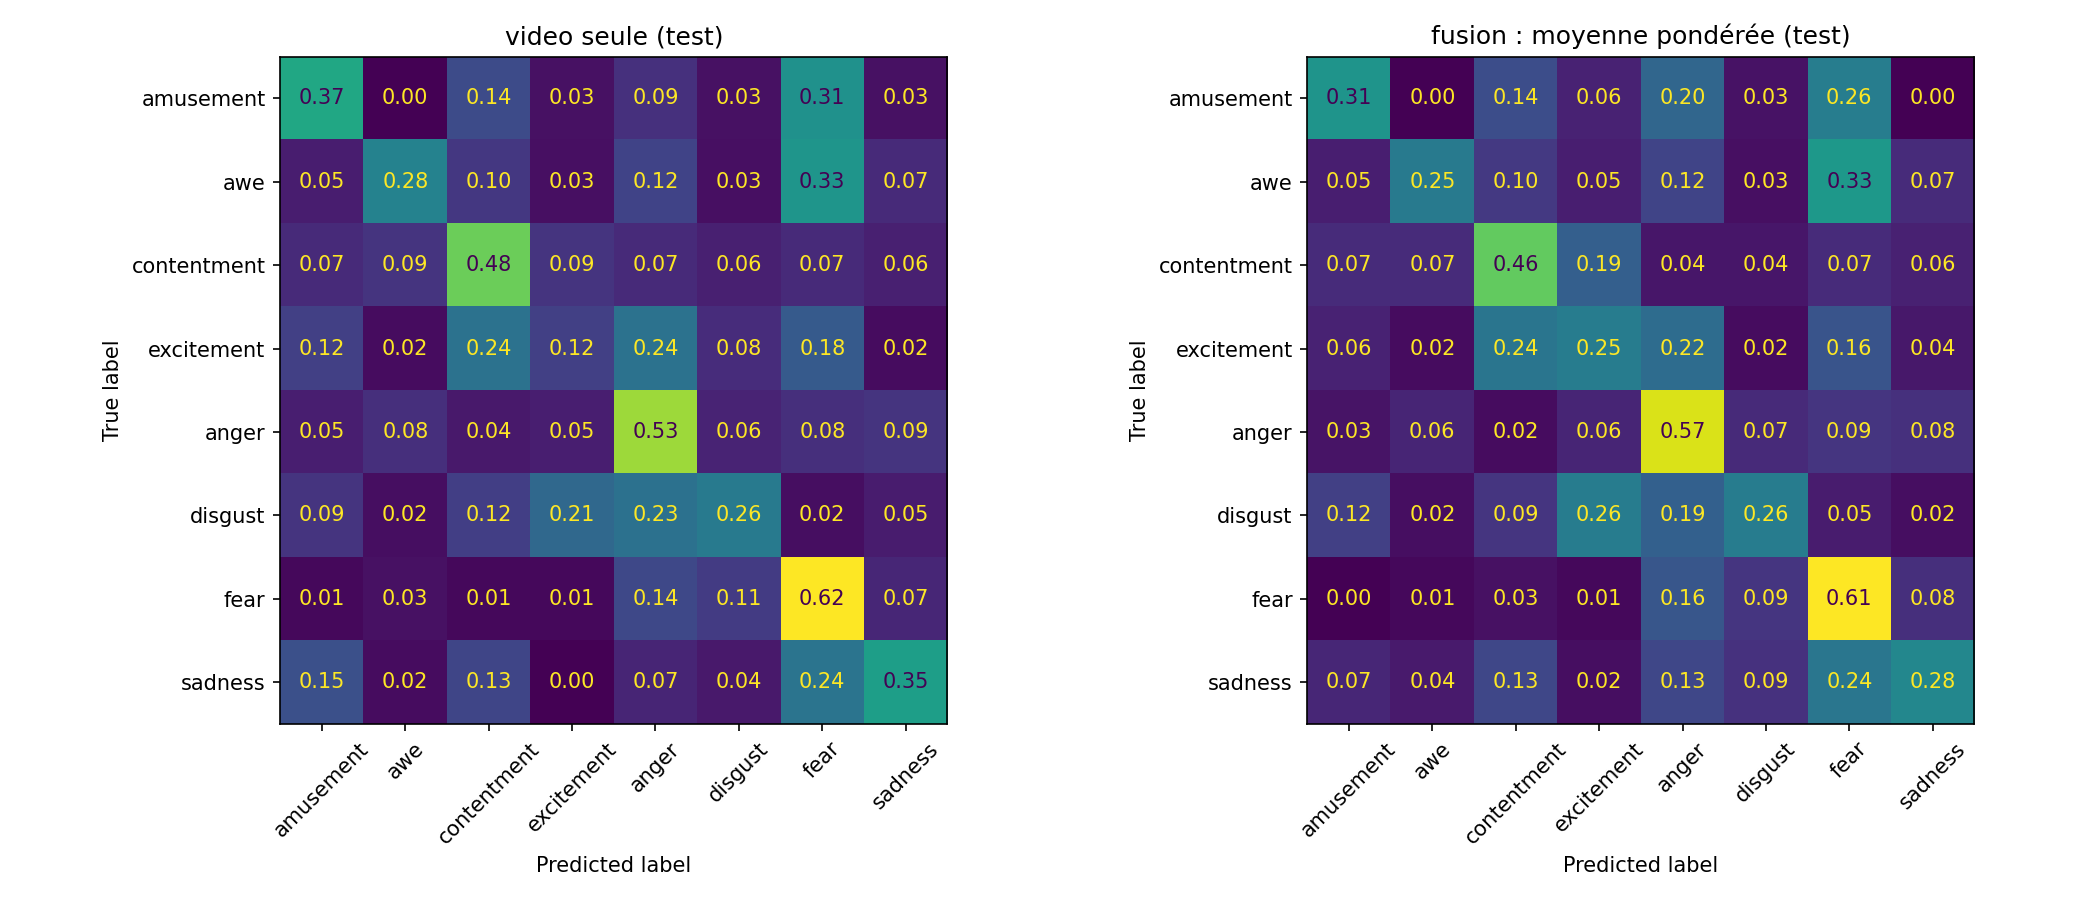

,méthode,masque,F1 dev,F1 test,IC95 test,exactitude dev,exactitude test,valence dev,valence test,retenu
0,video seule,—,0.390,0.369,"[0.308, 0.421]",0.405,0.410,0.724,0.686,NaN
1,audio seule,—,0.262,0.220,"[0.170, 0.260]",0.276,0.241,0.604,0.608,NaN
2,vote majoritaire,sans,0.362,0.338,"[0.273, 0.391]",0.380,0.380,0.695,0.674,NaN
3,max,sans,0.319,0.313,"[0.255, 0.362]",0.339,0.353,0.658,0.638,NaN
4,moyenne,sans,0.349,0.339,"[0.275, 0.389]",0.364,0.380,0.676,0.672,NaN
5,moyenne géométrique,sans,0.363,0.343,"[0.277, 0.392]",0.378,0.383,0.695,0.686,NaN
6,vote majoritaire,avec,0.372,0.338,"[0.275, 0.388]",0.391,0.380,0.699,0.677,NaN
7,max,avec,0.330,0.304,"[0.245, 0.353]",0.351,0.346,0.676,0.638,NaN
8,moyenne,avec,0.360,0.329,"[0.266, 0.378]",0.376,0.374,0.688,0.672,NaN
9,moyenne géométrique,avec,0.377,0.326,"[0.264, 0.377]",0.391,0.369,0.708,0.683,NaN


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from IPython.display import Image, display

# Probabilités fusionnées de la méthode retenue
nom, masque = CHOIX
am = masque == "avec"
for s in SPLITS:
    S = empiler(s, am)
    if nom.startswith("moyenne géométrique"):
        probs = moyenne_geo(S, POIDS.get((nom, am)))
    else:
        probs = moyenne(S, POIDS.get((nom, am)))
    out = pd.DataFrame(probs, columns=CLASSES)
    out.insert(0, "video_id", ref[s]["video_id"].values)
    out["prediction"] = [CLASSES[k] for k in PRED[CHOIX][s]]
    out["emotion"] = ref[s]["emotion"].values
    out.to_csv(OUT_DIR / f"probs_fusion_{s}.csv", index=False)
print("Fichiers prêts :", sorted(p.name for p in OUT_DIR.iterdir()))

# Réafficher les figures et le tableau récapitulatif
for png in ["choix_poids_dev.png", "confusion_test.png"]:
    display(Image(filename=str(OUT_DIR / png)))
display(pd.read_csv(OUT_DIR / "recapitulatif_fusion.csv").round(3))

# Télécharger le tout sur le PC (un seul fichier zip)
archive = shutil.make_archive("/content/resultats_fusion", "zip", OUT_DIR)
from google.colab import files
files.download(archive)